在notebook7-9当中，主要使用的是日数据进行回归，但是因为cpi等数据是月度/年度更新的，所以有很多数据不会跟随因子那样缓慢更新。因此，最后这个笔记本主要用于验证，在数据timeframe修改为月度情况下，数据滞后是否具有解释力。

In notebooks 7–9, the regressions mainly use daily data. However, because data such as CPI are updated monthly/annually, many data series do not update as slowly as the factors do. Therefore, this final notebook is mainly intended to verify whether data lags have explanatory power when the data timeframe is changed to monthly.

**月度预测设定 | Monthly forecasting setup**

本节读取 data/4_monthly_POS。初始训练区间为 2012-01-01 至 2024-12-31，POS 区间为 2025-01-01 至 2026-06-30，与第 7、8 本一致。每个月末预测下一完整月的汇率对数变化。月度文件已经按可用月份对齐，模型再滞后一个月，以限制预测时点的信息。

这里控制输入日期和递归估计顺序。源文件采用的发布日期假设及历史 IMF 预测版本限制仍然适用，无法据此宣称已经重建完整的历史实时数据库。第 9 本的宏观情景部分使用同期月度模型；本节检验滞后信息的样本外预测表现。

The initial training window is 2012-01-01 through 2024-12-31, followed by monthly POS forecasts for 2025-01-01 through 2026-06-30. Each month-end predicts the next complete month's FX log change. The availability-aligned monthly factors are lagged once more to match that forecast origin.

The code enforces dated inputs and sequential estimation. Results remain conditional on the source release-date assumptions and supplied historical IMF vintages. Notebook 9 uses a contemporaneous monthly model for its macro scenarios; this notebook evaluates predictions based on lagged information.


In [ ]:
# import libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown
from statsmodels.stats.multitest import multipletests

In [ ]:
# set up paths and constants
DATA = next(
    (p for p in [Path("data/4_monthly_POS"), Path("../data/4_monthly_POS")] if p.is_dir()),
    None,
)
if DATA is None:
    raise FileNotFoundError("Run from the project root or notebook directory.")

TRAIN_START, TRAIN_END = "2012-01-01", "2024-12-31"
POS_START, POS_END = "2025-01-01", "2026-06-30"
ALPHA, HAC_LAGS, ROLLING_MONTHS = 0.05, 12, 6
calendar = pd.date_range(TRAIN_START, POS_END, freq="ME")
pos_dates = pd.date_range(POS_START, POS_END, freq="ME")
FACTOR_FILES = {
    "CPI": "headline_cpi_log_change_monthly.csv",
    "GDP growth change": "gdp_annual_pct_change_monthly.csv",
    "Trade balance change": "trade_balance_annual_pct_change_monthly.csv",
    "FX reserves": "fx_reserves_log_change_monthly.csv",
    "Government debt / GDP": "general_government_gross_debt_annual_change_pp_monthly.csv",
}
factors = list(FACTOR_FILES)
continuous = ["fx_lag1", *factors]
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


**读取数据与单位核对 | Data and units**

下面对所有数据的数量，时间戳进行检查。所有文件必须与月度汇率的日期逐行一致。汇率、CPI 和外储保留 100 × 对数变化；GDP 和贸易保留原年度变化率，债务保留年度百分点变化。月度采样不会将年度指标变成月度增长率，本节不再次差分、不求和、不除以 12。年度来源标记仅用于追溯。

首次公布前的空值保留。下表的“最后数值变化月”只描述文件中的取值变化，不能代替正式发布日期记录。CPI 和外储在测试期后段长期沿用旧值，属于本次检验的数据限制。

The quantity and timestamps of all the data are checked below.All files must match the monthly FX calendar exactly. Existing log changes, annual percentage changes, and annual percentage-point changes retain their original units. No additional differencing, summation, or division by 12 is applied. Annual forecast/actual flags are retained for audit only.

Leading missing values remain missing. The last value-change month describes the supplied series, not an independently verified release date. CPI and reserves remain stale in the later POS months.


In [2]:
def read_monthly(filename):
    frame = pd.read_csv(DATA / filename)
    index = pd.DatetimeIndex(pd.to_datetime(frame.pop("date"), format="%Y/%m/%d"))
    if index.has_duplicates or not index.is_monotonic_increasing or not index.equals(calendar):
        raise ValueError(f"Monthly dates must match the reference calendar: {filename}")
    frame.index = index
    frame = frame.apply(pd.to_numeric, errors="raise")
    values = frame.to_numpy(dtype=float)
    if not np.isfinite(values[~np.isnan(values)]).all():
        raise ValueError(f"Nonfinite numeric value: {filename}")
    return frame

fx = read_monthly("USDSLE_monthly.csv").iloc[:, 0].rename("fx_change")
factor_frames = {name: read_monthly(filename) for name, filename in FACTOR_FILES.items()}
macro = pd.DataFrame({name: frame.iloc[:, 0] for name, frame in factor_frames.items()})
source_flags = pd.DataFrame({
    name: frame["is_prediction"] for name, frame in factor_frames.items()
    if "is_prediction" in frame
})
events = read_monthly("Sierra_Leone_Policy_Event_Dummies_monthly.csv")
if fx.isna().any() or not events.isin([0, 1]).all().all():
    raise ValueError("FX must be complete and events must be 0/1.")
for name in source_flags:
    if not source_flags[name].dropna().isin([0, 1]).all():
        raise ValueError(f"Invalid source flag: {name}")
    if not source_flags[name].isna().equals(macro[name].isna()):
        raise ValueError(f"Value and source flag availability differ: {name}")

audit_rows = []
for name in factors:
    values = macro[name].dropna()
    changed = values.loc[values.ne(values.shift(1))]
    audit_rows.append({
        "factor": name,
        "calendar_months": len(calendar),
        "missing_months": int(macro[name].isna().sum()),
        "first_available_month": values.index.min(),
        "last_value_change_month": changed.index.max(),
        "latest_supplied_value": values.iloc[-1],
    })
data_audit = pd.DataFrame(audit_rows).set_index("factor")
display(data_audit)


,calendar_months,missing_months,first_available_month,last_value_change_month,latest_supplied_value
factor,,,,,
CPI,174,2,2012-03-31,2025-04-30,0.242353
GDP growth change,174,17,2013-06-30,2026-06-30,7.3471
Trade balance change,174,17,2013-06-30,2025-07-31,37.8294
FX reserves,174,1,2012-02-29,2025-05-31,-4.24341
Government debt / GDP,174,17,2013-06-30,2026-04-30,-0.9


**预测时序与共同样本 | Forecast timing and common sample**

完整模型为：
The full model is:

$$
R_t=\alpha+\phi R_{t-1}+\beta^\top X_{t-1}^{avail}+\gamma^\top D_t+\varepsilon_t.
$$

滞后项在完整月历上生成，然后才删除缺失观察。所有对照模型使用同一组完整日期。事件项只控制初始训练期已经发生的事件；预测期输入设为 0。2021 年 8 月的两个事件列完全相同，合并为一个系数，来源名称均保留。事件控制用于历史拟合，未来事件冲击不由模型预测。

Lagged terms are generated on the full monthly calendar, and missing observations are removed only afterward. All comparison models use the same set of full dates. Event terms control only events that had already occurred during the initial training period; inputs for the forecast period are set to \(0\). The two event columns for August 2021 are identical and are merged into a single coefficient, while both source names are retained. Event controls are used for historical fitting; future event shocks are not predicted by the model.


In [3]:
def build_design(fx_values, macro_values, event_values):
    """Construct lagged inputs and event controls using the initial window only."""
    event_groups = {}
    historical_events = event_values.loc[:TRAIN_END]
    for name in event_values:
        values = historical_events[name]
        if values.nunique() > 1:
            event_groups.setdefault(tuple(values), []).append(name)
    policy = pd.DataFrame(index=fx_values.index, dtype=float)
    sources = {}
    for pattern, names in event_groups.items():
        historical = historical_events[names[0]]
        active_dates = historical.index[historical.eq(1)]
        if len(active_dates) != 1:
            raise ValueError(f"Expected one historical event month: {names}")
        term = f"P_{active_dates[0]:%Y_%m}"
        if term in policy:
            raise ValueError(f"Duplicate event month: {term}")
        policy[term] = 0.0
        policy.loc[historical.index, term] = historical.to_numpy()
        sources[term] = " + ".join(names)
    inputs = pd.concat(
        [fx_values.shift(1).rename("fx_lag1"), macro_values.shift(1), policy], axis=1
    )
    complete = pd.concat([fx_values.rename("fx_change"), inputs], axis=1).dropna()
    response = complete["fx_change"]
    design = sm.add_constant(complete.drop(columns="fx_change"), has_constant="add")
    return response, design, policy, sources

y_all, X_full, policy_X, policy_sources = build_design(fx, macro, events)
initial_dates = y_all.loc[:TRAIN_END].index
event_terms = list(policy_sources)
if not pos_dates.isin(y_all.index).all() or initial_dates[-1] != pd.Timestamp(TRAIN_END):
    raise ValueError("Incomplete initial training or POS period.")

origin_by_target = pd.Series(calendar, index=calendar).shift(1)
forecast_inputs = X_full.loc[pos_dates, continuous].copy()
forecast_inputs.insert(0, "forecast_origin", origin_by_target.loc[pos_dates])
for name in source_flags:
    forecast_inputs[f"is_prediction::{name}"] = source_flags[name].shift(1).loc[pos_dates]
assert X_full.loc[pos_dates, event_terms].eq(0).all().all()
assert (forecast_inputs["forecast_origin"] < forecast_inputs.index).all()

sample_summary = pd.DataFrame([{
    "requested_training_start": TRAIN_START,
    "effective_training_start": initial_dates.min(),
    "training_end": initial_dates.max(),
    "training_months": len(initial_dates),
    "excluded_training_months": int((calendar <= pd.Timestamp(TRAIN_END)).sum()) - len(initial_dates),
    "POS_first_target": pos_dates.min(),
    "POS_last_target": pos_dates.max(),
    "POS_months": len(pos_dates),
    "historical_event_terms": len(event_terms),
    "full_model_parameters": X_full.shape[1],
}])
display(sample_summary)
display(forecast_inputs.iloc[[0, 1, -2, -1]])


,requested_training_start,effective_training_start,training_end,training_months,excluded_training_months,POS_first_target,POS_last_target,POS_months,historical_event_terms,full_model_parameters
0,2012-01-01,2013-07-31,2024-12-31,138,18,2025-01-31,2026-06-30,18,5,12


,forecast_origin,fx_lag1,CPI,GDP growth change,Trade balance change,FX reserves,Government debt / GDP,is_prediction::GDP growth change,is_prediction::Trade balance change,is_prediction::Government debt / GDP
2025-01-31,2024-12-31,0.192765,-0.148611,-19.0685,17.2491,3.04488,-2.483,1,0,1
2025-02-28,2025-01-31,-0.369977,0.84203,-19.0685,17.2491,14.1713,-2.483,1,0,1
2026-05-31,2026-04-30,-0.209266,0.242353,2.85591,37.8294,-4.24341,-0.9,1,1,1
2026-06-30,2026-05-31,-0.352979,0.242353,2.85591,37.8294,-4.24341,-0.9,1,1,1


**回归、显著性与模型比较 | Regression, inference, and model comparison**

比较六种含截距的模型：仅事件、仅 AR(1)、仅五个宏观因子、AR(1)＋事件、AR(1)与五因子、完整模型。“仅事件”不含 AR 项或宏观因子，“仅宏观因子”不含 AR 项或事件项。AR(1)与事件为评估完整模型宏观增量的对照。

采用 OLS 系数与 HAC(12) 标准误，Bartlett 权重、有限样本修正和渐近正态检验。这里 12 代表 12 个月。每个含宏观因子的模型分别进行五因子 Holm 校正及联合 Wald 检验。置信区间为逐项 95% 区间。

Compare six models with an intercept: events only, AR(1) only, the five macro factors only, AR(1) + events, AR(1) + the five factors, and the full model. “Events only” contains no AR term or macro factors, and “macro factors only” contains no AR term or event terms. The AR(1) + events model serves as the control for assessing the incremental contribution of the macro factors in the full model.

Use OLS coefficients and HAC(12) standard errors, with Bartlett weights, a finite-sample correction, and asymptotic normal tests. Here, 12 denotes 12 months. For each model containing macro factors, perform Holm correction across the five factors and a joint Wald test separately. Confidence intervals are per-coefficient 95% intervals.


In [ ]:
MODEL_LABELS = {
    "events_only": "Events only",
    "ar1": "AR(1) only",
    "macro_only": "Macro only",
    "ar1_events": "AR(1) + events",
    "ar1_macro": "AR(1) + macro",
    "full": "Full: AR(1) + macro + events",
}
MODEL_COLUMNS = {
    "events_only": ["const", *event_terms],
    "ar1": ["const", "fx_lag1"],
    "macro_only": ["const", *factors],
    "ar1_events": ["const", "fx_lag1", *event_terms],
    "ar1_macro": ["const", "fx_lag1", *factors],
    "full": ["const", *continuous, *event_terms],
}

def fit_hac(response, design):
    if not response.index.equals(design.index):
        raise ValueError("Response and predictor dates differ.")
    if len(response) <= design.shape[1] or np.linalg.matrix_rank(design.to_numpy()) != design.shape[1]:
        raise ValueError("The model must have positive residual df and a full-rank design.")
    return sm.OLS(response, design, missing="raise").fit(
        cov_type="HAC",
        cov_kwds={"maxlags": HAC_LAGS, "kernel": "bartlett", "use_correction": True},
        use_t=False,
    )

def coefficient_table(fit):
    terms = [name for name in ["const", *continuous] if name in fit.params]
    ci = fit.conf_int(alpha=ALPHA).loc[terms]
    table = pd.DataFrame({
        "beta": fit.params.loc[terms],
        "HAC_SE": fit.bse.loc[terms],
        "z": fit.tvalues.loc[terms],
        "p_HAC": fit.pvalues.loc[terms],
        "CI95_low": ci[0],
        "CI95_high": ci[1],
    })
    table["p_Holm_5_factors"] = np.nan
    table["reject_5pct"] = table["p_HAC"] < ALPHA
    if set(factors).issubset(terms):
        adjusted = multipletests(table.loc[factors, "p_HAC"], method="holm")[1]
        table.loc[factors, "p_Holm_5_factors"] = adjusted
        table.loc[factors, "reject_5pct"] = adjusted < ALPHA
    return table

def macro_joint(fit):
    if not set(factors).issubset(fit.params.index):
        return np.nan, np.nan
    restrictions = np.eye(len(fit.params))[[fit.params.index.get_loc(name) for name in factors]]
    test = fit.wald_test(restrictions, use_f=False, scalar=True)
    return float(test.statistic), float(test.pvalue)

initial_models = {
    key: fit_hac(y_all.loc[initial_dates], X_full.loc[initial_dates, columns])
    for key, columns in MODEL_COLUMNS.items()
}
comparison_rows = []
for key, fit in initial_models.items():
    comparison_rows.append({
        "model": MODEL_LABELS[key],
        "n": int(fit.nobs),
        "parameters": len(fit.params),
        "R2": fit.rsquared,
        "adjusted_R2": fit.rsquared_adj,
        "RMSE": np.sqrt(np.mean(fit.resid ** 2)),
        "MAE": np.mean(np.abs(fit.resid)),
        "AIC": fit.aic,
        "BIC": fit.bic,
    })
model_comparison = pd.DataFrame(comparison_rows).set_index("model")
initial_coefficients = pd.concat(
    {MODEL_LABELS[key]: coefficient_table(fit) for key, fit in initial_models.items()},
    names=["model", "term"],
)
joint_rows = []
for key in ["macro_only", "ar1_macro", "full"]:
    statistic, p_value = macro_joint(initial_models[key])
    joint_rows.append({
        "model": MODEL_LABELS[key], "chi2": statistic, "df": len(factors),
        "p_HAC": p_value, "reject_5pct": p_value < ALPHA,
    })
macro_joint_tests = pd.DataFrame(joint_rows).set_index("model")
event_coefficients = pd.DataFrame({"source_events": pd.Series(policy_sources)})
for key in ["events_only", "ar1_events", "full"]:
    event_coefficients[MODEL_LABELS[key]] = initial_models[key].params.loc[event_terms]

# display tables
display(model_comparison)
display(initial_coefficients)
display(macro_joint_tests)
display(event_coefficients)


,n,parameters,R2,adjusted_R2,RMSE,MAE,AIC,BIC
model,,,,,,,,
Events only,138,6,0.432554,0.411059,3.8316,1.94377,774.373,791.936
AR(1) only,138,2,0.0200119,0.0128061,5.03533,2.51782,841.775,847.63
Macro only,138,6,0.0661462,0.030773,4.91538,2.27723,843.121,860.684
AR(1) + events,138,7,0.445322,0.419917,3.78824,2.02516,773.232,793.723
AR(1) + macro,138,7,0.101818,0.0606797,4.82058,2.31089,839.746,860.237
Full: AR(1) + macro + events,138,12,0.549533,0.510206,3.41389,1.79917,754.514,789.641


beta      HAC_SE  \
model                        term                                            
Events only                  const                     1.18953    0.447942   
AR(1) only                   const                     1.38277    0.450618   
                             fx_lag1                 -0.141433    0.100568   
Macro only                   const                   -0.119542    0.399846   
                             CPI                      0.555049    0.350051   
                             GDP growth change      0.00457858  0.00135358   
                             Trade balance change  -0.00405266  0.00243873   
                             FX reserves             0.0593962   0.0531604   
                             Government debt / GDP   0.0584964   0.0498731   
AR(1) + events               const                     1.32311    0.450723   
                             fx_lag1                 -0.113619   0.0965393   
AR(1) + macro                const                  -0.0528457    0.402938   
                             fx_lag1                 -0.193794   0.0929248   
                             CPI                      0.628287    0.376188   
                             GDP growth change      0.00541265  0.00153538   
                             Trade balance change   -0.0041346  0.00253782   
                             FX reserves             0.0585777   0.0560193   
                             Government debt / GDP   0.0740544   0.0610522   
Full: AR(1) + macro + events const                   -0.322865    0.371854   
                             fx_lag1                 -0.190381   0.0895801   
                             CPI                      0.885654    0.315772   
                             GDP growth change       0.0054523   0.0014243   
                             Trade balance change  -0.00138359 0.000845615   
                             FX reserves             0.0407456   0.0465258   
                             Government debt / GDP    0.112698   0.0837913   

                                                           z       p_HAC  \
model                        term                                          
Events only                  const                   2.65554   0.0079181   
AR(1) only                   const                    3.0686  0.00215061   
                             fx_lag1                -1.40634    0.159623   
Macro only                   const                 -0.298971    0.764962   
                             CPI                     1.58562    0.112825   
                             GDP growth change       3.38257 0.000718117   
                             Trade balance change   -1.66179   0.0965545   
                             FX reserves              1.1173    0.263865   
                             Government debt / GDP   1.17291    0.240834   
AR(1) + events               const                   2.93552  0.00332985   
                             fx_lag1                -1.17692    0.239229   
AR(1) + macro                const                 -0.131151    0.895656   
                             fx_lag1                -2.08549    0.037025   
                             CPI                     1.67014   0.0948917   
                             GDP growth change       3.52529 0.000423017   
                             Trade balance change   -1.62919    0.103272   
                             FX reserves             1.04567    0.295714   
                             Government debt / GDP   1.21297    0.225142   
Full: AR(1) + macro + events const                 -0.868257    0.385254   
                             fx_lag1                -2.12526   0.0335647   
                             CPI                     2.80473   0.0050359   
                             GDP growth change       3.82806 0.000129155   
                             Trade balance change    -1.6362    0.101799   
                             FX reserves           

,chi2,df,p_HAC,reject_5pct
model,,,,
Macro only,21.3334,5,0.0007006,True
AR(1) + macro,25.6577,5,0.000103964,True
Full: AR(1) + macro + events,24.475,5,0.000175918,True


,source_events,Events only,AR(1) + events,Full: AR(1) + macro + events
P_2015_11,D_IMF_ECF_REVIEW_2015,-8.89462,-8.20778,-5.20745
P_2016_06,D_Brexit referendum_2016,33.2399,33.0947,34.5368
P_2021_08,D_REDENOM_ANNOUNCE_2021 + D_SDR_ALLOCATION_2021,-0.230146,-0.385744,1.30112
P_2023_06,D_IMF_ECF_REVIEW_A_2023,-18.8607,-18.8219,-21.4153
P_2023_11,D_IMF_ECF_REVIEW_B_2023,-2.15856,-2.08166,-3.21407


**训练样本图表 | Training-sample charts**

第一组图比较六个模型的 R² 与调整后 R²，并展示完整模型的样本内拟合、残差和残差分布。第二组图展示 AR 项和五个宏观系数的逐项 95% HAC 区间，各子图使用独立横轴以保留原单位。区间跨越零与 Holm 校正后的判断可能不同。所有图仅使用初始训练样本。

The first figure compares training R² and adjusted R² and displays the full model's fitted changes and residuals. The second figure shows pointwise 95% HAC intervals for the AR term and five macro coefficients, using separate scales. These intervals are not adjusted for multiple testing. All observations end in December 2024.


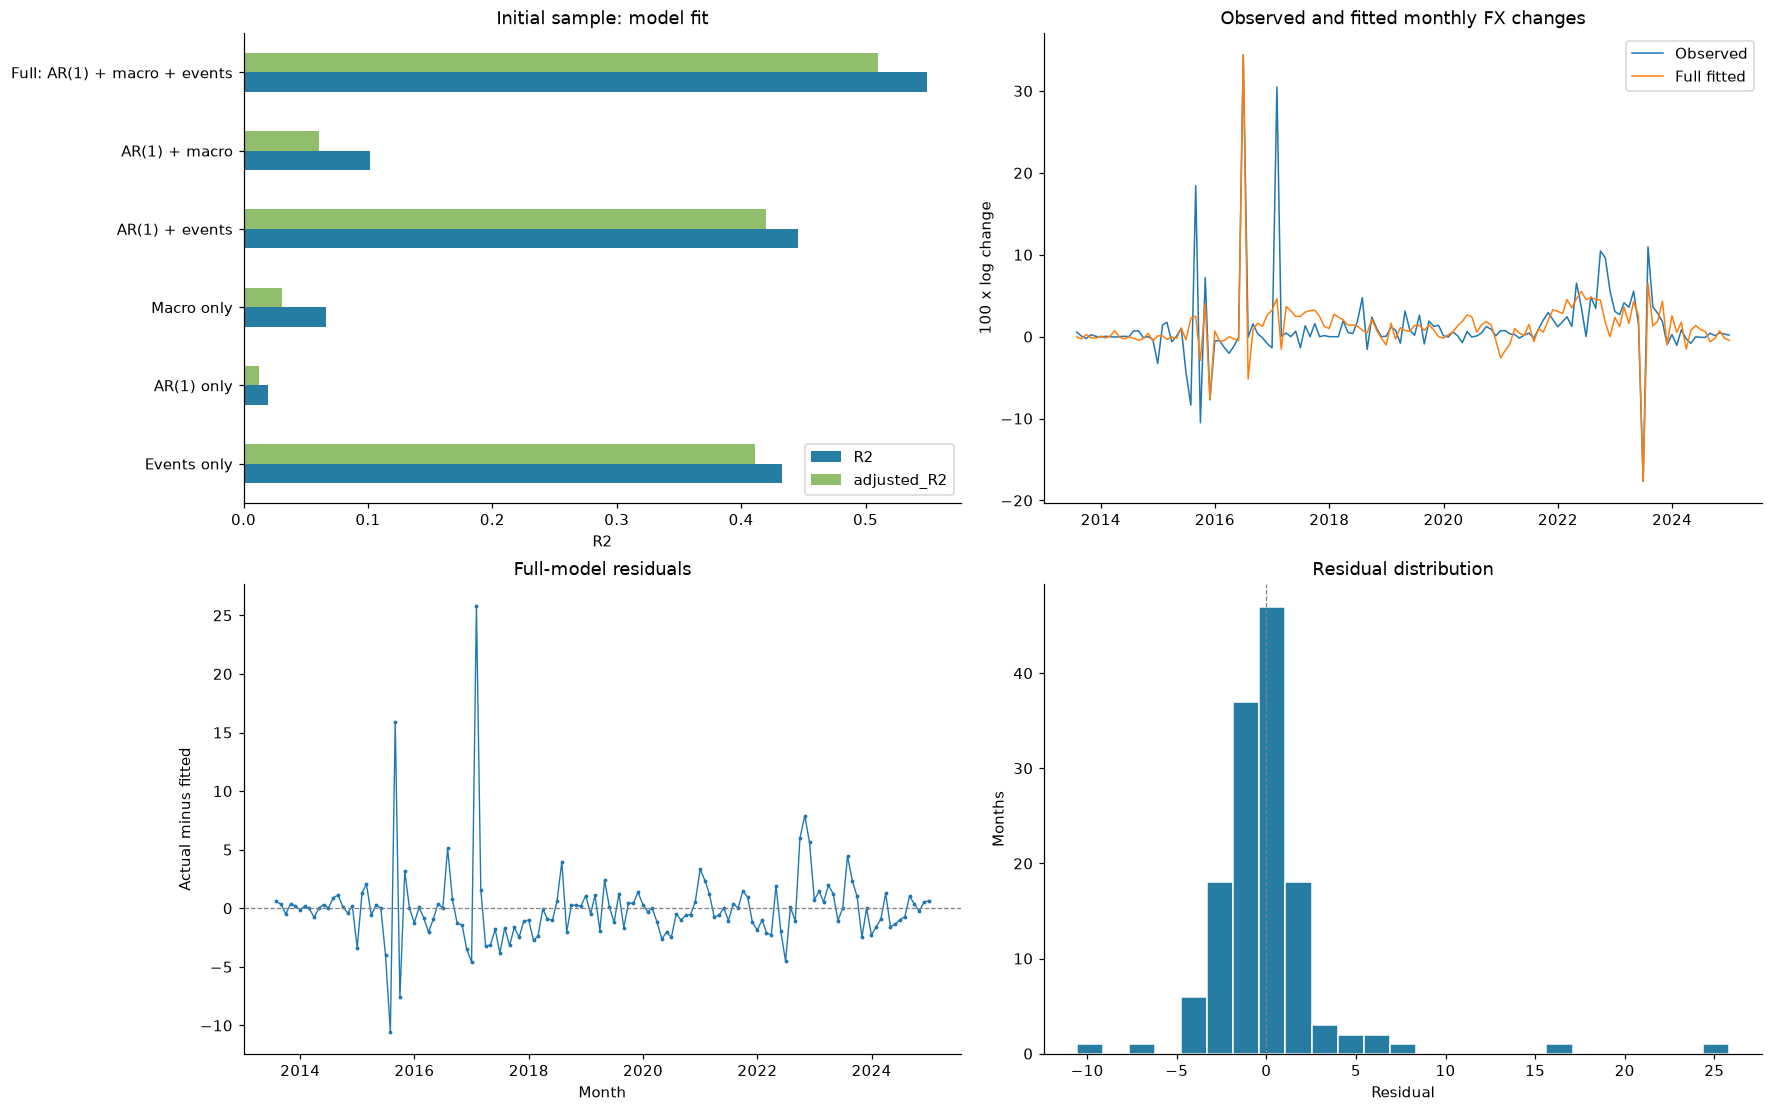

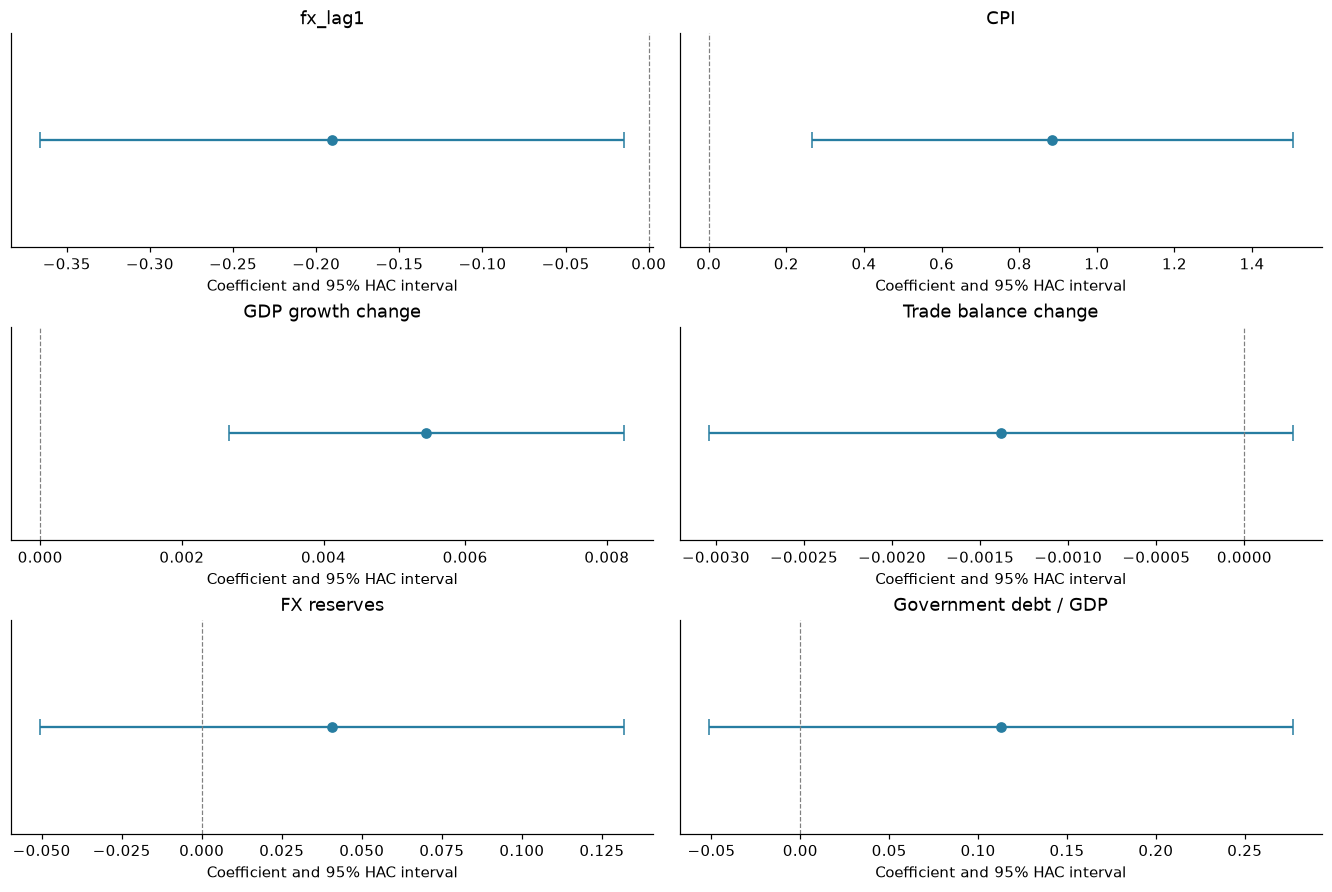

In [5]:
initial_full = initial_models["full"]
fig, axes = plt.subplots(2, 2, figsize=(16, 10), layout="constrained")
model_comparison[["R2", "adjusted_R2"]].plot.barh(ax=axes[0, 0], color=["#277DA1", "#90BE6D"])
axes[0, 0].set(title="Initial sample: model fit", xlabel="R2", ylabel="")
axes[0, 1].plot(initial_dates, y_all.loc[initial_dates], label="Observed", linewidth=1)
axes[0, 1].plot(initial_dates, initial_full.fittedvalues, label="Full fitted", linewidth=1)
axes[0, 1].set(title="Observed and fitted monthly FX changes", ylabel="100 x log change")
axes[0, 1].legend()
axes[1, 0].plot(initial_dates, initial_full.resid, linewidth=0.9, marker=".", markersize=3)
axes[1, 0].axhline(0, color="grey", linestyle="--", linewidth=0.8)
axes[1, 0].set(title="Full-model residuals", ylabel="Actual minus fitted", xlabel="Month")
axes[1, 1].hist(initial_full.resid, bins=25, edgecolor="white", color="#277DA1")
axes[1, 1].axvline(0, color="grey", linestyle="--", linewidth=0.8)
axes[1, 1].set(title="Residual distribution", xlabel="Residual", ylabel="Months")
plt.show()

full_coefficient_table = coefficient_table(initial_full)
fig, axes = plt.subplots(3, 2, figsize=(12, 8), layout="constrained")
for ax, term in zip(axes.flat, continuous):
    row = full_coefficient_table.loc[term]
    ax.errorbar(
        row["beta"], 0,
        xerr=[[row["beta"] - row["CI95_low"]], [row["CI95_high"] - row["beta"]]],
        fmt="o", color="#277DA1", capsize=5,
    )
    ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
    ax.set(title=term, yticks=[], xlabel="Coefficient and 95% HAC interval")
plt.show()


**解读 | Interpretation**

在进行月度数据回归之后并剔除未来函数之后，可以看到宏观因子的解释力仍然有限，并且与notebook6中的数据进行比较后发现，Rs数值从0.14下降到0.10，说明数据滞后处理使整个解释力下降，主要的解释力还是来自事件驱动。如果将宏观因子与事件结合，整体Rs维持在0.54，adj_Rs 达到0.50以上。残差表现方面，符合广义范围的正态分布，包含极端值。**这个测试证明了，notebook7-8当中的回归与测试导致Rs下降的主要原因是周期不匹配。**

After performing the monthly data regression and removing look-ahead bias, it can be seen that the explanatory power of the macro factors remains limited. Compared with the data in notebook 6, the \(R^2\) value drops from 0.14 to 0.10, indicating that the lagged data treatment reduces the overall explanatory power; the main explanatory power still comes from event-driven factors. When the macro factors are combined with events, the overall \(R^2\) remains at 0.54, and the adjusted \(R^2\) reaches above 0.50. In terms of residual behavior, the residuals are broadly consistent with a normal distribution and include extreme values. **This test demonstrates that the main reason for the decline in \(R^2\) in the regressions and tests in notebooks 7–8 is a timeframe mismatch.**

**逐月 POS 循环 | Monthly expanding-window POS**

每个月使用上月末训练得到的参数预测，随后读取当月实际汇率变化、记录误差，再加入当月观察并重新估计六个模型。预测期的事件输入始终为 0。“仅事件”模型因此依靠其截距预测。另保留固定初始完整模型和零变化预测；固定模型的参数不更新，输入仍按月更新。

参数和训练指标保存拟合截止月及最早可用月份。点预测不添加随机噪声，也不根据测试期 p 值或误差选择变量。最后一次重估后的参数可从 2026 年 7 月开始使用，不能回用于已经评分的 6 月预测。

At each month-end, the previously fitted models forecast the next target. Only after predictions are saved is the actual outcome read, scored, and added to the expanding window. All six models are re-estimated. Historical event inputs remain zero during POS. A fixed-coefficient full model and a zero-change benchmark are also scored.

Updated parameters become usable in the following month. Point forecasts contain no simulated noise. No model or variable is selected using POS errors or repeated p-values.


In [6]:
FORECAST_LABELS = {
    **MODEL_LABELS,
    "full_fixed": "Full, fixed coefficients",
    "zero_change": "Zero change",
}

def run_expanding_pos(response, design, target_dates, starting_models):
    current = dict(starting_models)
    fit_through = pd.Timestamp(TRAIN_END)
    forecasts, training_rows, parameter_rows = [], [], []

    def save_state(key, fit, cutoff):
        _, joint_p = macro_joint(fit)
        training_rows.append({
            "model": key, "fit_through": cutoff,
            "usable_from": cutoff + pd.offsets.MonthEnd(1),
            "n": int(fit.nobs), "training_R2": fit.rsquared,
            "training_adjusted_R2": fit.rsquared_adj,
            "training_RMSE": np.sqrt(np.mean(fit.resid ** 2)),
            "p_five_macro_joint_HAC": joint_p,
        })
        parameter_rows.append({
            "model": key, "fit_through": cutoff,
            "usable_from": cutoff + pd.offsets.MonthEnd(1),
            **fit.params.to_dict(),
        })

    for key, fit in current.items():
        save_state(key, fit, fit_through)
    for target in target_dates:
        origin = target - pd.offsets.MonthEnd(1)
        if fit_through != origin:
            raise ValueError("The fitted model must end in the preceding month.")
        # Predictions are computed before accessing the current target outcome.
        predictions = {
            key: float(current[key].predict(design.loc[[target], columns]).iloc[0])
            for key, columns in MODEL_COLUMNS.items()
        }
        predictions["full_fixed"] = float(
            starting_models["full"].predict(design.loc[[target], MODEL_COLUMNS["full"]]).iloc[0]
        )
        predictions["zero_change"] = 0.0
        record = {
            "target_date": target, "forecast_origin": origin, "training_end": fit_through,
            "n_train_before_forecast": int(current["full"].nobs),
            "n_train_fixed_model": int(starting_models["full"].nobs),
        }
        actual = float(response.loc[target])
        record["actual"] = actual
        for key, prediction in predictions.items():
            error = actual - prediction
            record[f"prediction::{key}"] = prediction
            record[f"error::{key}"] = error
            record[f"abs_error::{key}"] = abs(error)
            record[f"squared_error::{key}"] = error ** 2
        forecasts.append(record)

        observed_dates = response.index[response.index <= target]
        current = {
            key: fit_hac(response.loc[observed_dates], design.loc[observed_dates, columns])
            for key, columns in MODEL_COLUMNS.items()
        }
        fit_through = target
        for key, fit in current.items():
            save_state(key, fit, fit_through)

    return (
        pd.DataFrame(forecasts).set_index("target_date"),
        pd.DataFrame(training_rows),
        pd.DataFrame(parameter_rows),
        current,
    )

forecast_log, training_history, parameter_history, final_models = run_expanding_pos(
    y_all, X_full, pos_dates, initial_models
)
assert forecast_log.index.equals(pos_dates)
assert (forecast_log["training_end"] == forecast_inputs["forecast_origin"]).all()
assert np.array_equal(
    forecast_log["n_train_before_forecast"].to_numpy(),
    len(initial_dates) + np.arange(len(pos_dates)),
)
assert len(training_history) == len(MODEL_COLUMNS) * (len(pos_dates) + 1)
display(forecast_log[[
    "forecast_origin", "n_train_before_forecast", "actual",
    *[f"prediction::{key}" for key in FORECAST_LABELS],
]])
display(training_history.loc[
    training_history["fit_through"].isin([pd.Timestamp(TRAIN_END), pd.Timestamp(POS_END)])
].set_index(["model", "fit_through"]))


,forecast_origin,n_train_before_forecast,actual,prediction::events_only,prediction::ar1,prediction::macro_only,prediction::ar1_events,prediction::ar1_macro,prediction::full,prediction::full_fixed,prediction::zero_change
target_date,,,,,,,,,,,
2025-01-31,2024-12-31,138,-0.369977,1.18953,1.3555,-0.323631,1.30121,-0.363616,-0.774777,-0.774777,0
2025-02-28,2025-01-31,139,0.398617,1.17789,1.42192,0.885804,1.35196,1.01943,0.674258,0.663074,0
2025-03-31,2025-02-28,140,-0.259826,1.17212,1.30592,-0.828052,1.25762,-0.904948,-1.1807,-1.19089,0
2025-04-30,2025-03-31,141,0.226338,1.16159,1.38684,0.0142821,1.32024,0.144888,0.105872,0.0813611,0
2025-05-31,2025-04-30,142,-0.045403,1.15476,1.31008,-0.103047,1.2572,-0.124143,-0.408894,-0.433121,0
2025-06-30,2025-05-31,143,-0.120881,1.14607,1.33813,-0.518633,1.2778,-0.47723,-0.633472,-0.680142,0
2025-07-31,2025-06-30,144,-0.388336,1.13695,1.33789,-0.198124,1.27559,-0.144284,-0.543937,-0.601804,0
2025-08-31,2025-07-31,145,0.202318,1.12606,1.36218,-0.634577,1.29257,-0.539153,-0.632868,-0.699102,0
2025-09-30,2025-08-31,146,0.334232,1.11951,1.27212,-0.612287,1.21909,-0.633778,-0.722309,-0.811551,0


,,usable_from,n,training_R2,training_adjusted_R2,training_RMSE,p_five_macro_joint_HAC
model,fit_through,,,,,,
events_only,2024-12-31,2025-01-31,138,0.432554,0.411059,3.8316,NaN
ar1,2024-12-31,2025-01-31,138,0.0200119,0.0128061,5.03533,NaN
macro_only,2024-12-31,2025-01-31,138,0.0661462,0.030773,4.91538,0.0007006
ar1_events,2024-12-31,2025-01-31,138,0.445322,0.419917,3.78824,NaN
ar1_macro,2024-12-31,2025-01-31,138,0.101818,0.0606797,4.82058,0.000103964
full,2024-12-31,2025-01-31,138,0.549533,0.510206,3.41389,0.000175918
events_only,2026-06-30,2026-07-31,156,0.42984,0.410834,3.62487,NaN
ar1,2026-06-30,2026-07-31,156,0.0180687,0.0116925,4.75702,NaN
macro_only,2026-06-30,2026-07-31,156,0.0716752,0.040731,4.62534,0.000315263


**样本外误差与最终系数 | Forecast accuracy and final coefficients**

分别报告全部 18 个月、2025 年和 2026 年上半年的 RMSE、MAE、平均误差，以及相对零变化、AR(1)、AR(1)＋事件的样本外 R²：

$$
R^2_{\mathrm{OS},b}=1-\frac{\sum_t(R_t-\widehat R_t)^2}{\sum_t(R_t-\widehat R_{t,b})^2}.
$$

该指标大于 0 表示在相同评价月份上均方误差小于基准。相对评价期均值的 R² 单独列出，它只作为事后描述。初始与最终系数、p 值用于展示模型更新，不作为重新挑选模型的依据。18 个样本外月份较少，各子区间的结果也可能不稳定。

RMSE, MAE, mean error, and benchmark-relative out-of-sample R² are reported for all 18 forecasts, calendar 2025, and 2026 H1. Positive benchmark-relative R² means lower squared forecast error on the same dates. R² relative to the realized evaluation-period mean is reported separately as an ex-post descriptive measure.

Initial and final coefficient estimates document updating; they do not drive model selection. The short evaluation window limits conclusions about stability.


In [7]:
def summarize_forecasts(frame, period_name):
    mean_sst = float(np.sum((frame["actual"] - frame["actual"].mean()) ** 2))
    baseline_sse = {
        "zero": float(frame["squared_error::zero_change"].sum()),
        "AR1": float(frame["squared_error::ar1"].sum()),
        "AR1_events": float(frame["squared_error::ar1_events"].sum()),
    }
    rows = []
    for key, label in FORECAST_LABELS.items():
        errors = frame[f"error::{key}"]
        sse = float(np.sum(errors ** 2))
        row = {
            "period": period_name, "model": label, "n": len(frame),
            "RMSE": np.sqrt(np.mean(errors ** 2)), "MAE": np.mean(np.abs(errors)),
            "ME_actual_minus_predicted": np.mean(errors),
            "R2_vs_period_mean": 1 - sse / mean_sst if mean_sst > 0 else np.nan,
        }
        row.update({
            f"R2_vs_{name}": 1 - sse / denominator if denominator > 0 else np.nan
            for name, denominator in baseline_sse.items()
        })
        rows.append(row)
    return pd.DataFrame(rows)

FULL_PERIOD = "2025-01 to 2026-06"
accuracy_summary = pd.concat([
    summarize_forecasts(forecast_log, FULL_PERIOD),
    summarize_forecasts(forecast_log.loc["2025"], "2025"),
    summarize_forecasts(forecast_log.loc["2026"], "2026 H1"),
], ignore_index=True).set_index(["period", "model"])
display(accuracy_summary)

parameter_change = pd.DataFrame({
    "initial_full": initial_models["full"].params,
    "final_full": final_models["full"].params,
})
parameter_change["change"] = parameter_change["final_full"] - parameter_change["initial_full"]
final_coefficients = pd.concat({
    "Initial full model": coefficient_table(initial_models["full"]),
    "Full model after 2026-06 update": coefficient_table(final_models["full"]),
}, names=["fit", "term"])
display(parameter_change)
display(final_coefficients)

running_accuracy = pd.DataFrame(index=pos_dates)
for key in FORECAST_LABELS:
    squared = forecast_log[f"squared_error::{key}"]
    running_accuracy[f"cumulative_RMSE::{key}"] = np.sqrt(squared.expanding().mean())
    running_accuracy[f"rolling_RMSE::{key}"] = np.sqrt(
        squared.rolling(ROLLING_MONTHS, min_periods=ROLLING_MONTHS).mean()
    )


n     RMSE      MAE  \
period             model                                                
2025-01 to 2026-06 Events only                   18  1.15387  1.10854   
                   AR(1) only                    18  1.32199  1.28644   
                   Macro only                    18 0.429785 0.327573   
                   AR(1) + events                18  1.26637   1.2285   
                   AR(1) + macro                 18 0.403748 0.298988   
                   Full: AR(1) + macro + events  18  0.45658  0.34549   
                   Full, fixed coefficients      18 0.487564 0.371406   
                   Zero change                   18 0.314732 0.266421   
2025               Events only                   12  1.18859  1.13488   
                   AR(1) only                    12  1.35655   1.3162   
                   Macro only                    12 0.494337 0.379641   
                   AR(1) + events                12  1.30128  1.25792   
                   AR(1) + macro                 12 0.476121 0.360774   
                   Full: AR(1) + macro + events  12 0.539827 0.443098   
                   Full, fixed coefficients      12 0.577901 0.477845   
                   Zero change                   12 0.345854 0.296059   
2026 H1            Events only                    6  1.08109  1.05588   
                   AR(1) only                     6     1.25  1.22692   
                   Macro only                     6 0.255749 0.223438   
                   AR(1) + events                 6  1.19347  1.16965   
                   AR(1) + macro                  6 0.188826 0.175415   
                   Full: AR(1) + macro + events   6 0.206325 0.150273   
                   Full, fixed coefficients       6 0.212647 0.158529   
                   Zero change                    6 0.240706 0.207145   

                                                 ME_actual_minus_predicted  \
period             model                                                     
2025-01 to 2026-06 Events only                                    -1.10854   
                   AR(1) only                                     -1.28644   
                   Macro only                                     0.225782   
                   AR(1) + events                                  -1.2285   
                   AR(1) + macro                                  0.158579   
                   Full: AR(1) + macro + events                   0.232707   
                   Full, fixed coefficients                       0.294472   
                   Zero change                                   0.0111284   
2025               Events only                                    -1.13488   
                   AR(1) only                                      -1.3162   
                   Macro only                                     0.259017   
                   AR(1) + events                                 -1.25792   
                   AR(1) + macro                                  0.214945   
                   Full: AR(1) + macro + events                   0.369784   
                   Full, fixed coefficients                       0.419726   
                   Zero change                                   0.0068278   
2026 H1            Events only                                    -1.05588   
                   AR(1) only                                     -1.22692   
                   Macro only                                     0.159313   
                   AR(1) + events                                 -1.16965   
                   AR(1) + macro                                 0.0458461   
                   Full: AR(1) + macro + events                 -0.0414469   
                   Full, fixed coefficients                      0.0439631   
                   Zero change                                   0.0197295   

                                                 R2_vs_period_mean  \
period             model                            

,initial_full,final_full,change
const,-0.322865,-0.241555,0.0813099
fx_lag1,-0.190381,-0.190308,7.35716e-05
CPI,0.885654,0.863173,-0.0224814
GDP growth change,0.0054523,0.00538355,-6.87458e-05
Trade balance change,-0.00138359,-0.00129842,8.51699e-05
FX reserves,0.0407456,0.0355167,-0.00522885
Government debt / GDP,0.112698,0.105289,-0.00740904
P_2015_11,-5.20745,-5.25182,-0.0443747
P_2016_06,34.5368,34.5381,0.00133371
P_2021_08,1.30112,1.22068,-0.0804421


beta      HAC_SE  \
fit                             term                                            
Initial full model              const                   -0.322865    0.371854   
                                fx_lag1                 -0.190381   0.0895801   
                                CPI                      0.885654    0.315772   
                                GDP growth change       0.0054523   0.0014243   
                                Trade balance change  -0.00138359 0.000845615   
                                FX reserves             0.0407456   0.0465258   
                                Government debt / GDP    0.112698   0.0837913   
Full model after 2026-06 update const                   -0.241555     0.28079   
                                fx_lag1                 -0.190308   0.0891172   
                                CPI                      0.863173    0.282725   
                                GDP growth change      0.00538355  0.00140977   
                                Trade balance change  -0.00129842 0.000787285   
                                FX reserves             0.0355167   0.0391635   
                                Government debt / GDP    0.105289   0.0770281   

                                                              z       p_HAC  \
fit                             term                                          
Initial full model              const                 -0.868257    0.385254   
                                fx_lag1                -2.12526   0.0335647   
                                CPI                     2.80473   0.0050359   
                                GDP growth change       3.82806 0.000129155   
                                Trade balance change    -1.6362    0.101799   
                                FX reserves            0.875762    0.381159   
                                Government debt / GDP   1.34498     0.17863   
Full model after 2026-06 update const                 -0.860269    0.389641   
                                fx_lag1                -2.13547   0.0327223   
                                CPI                     3.05305   0.0022653   
                                GDP growth change       3.81873 0.000134138   
                                Trade balance change   -1.64924   0.0990982   
                                FX reserves            0.906883    0.364469   
                                Government debt / GDP   1.36689     0.17166   

                                                         CI95_low   CI95_high  \
fit                             term                                            
Initial full model              const                    -1.05169    0.405956   
                                fx_lag1                 -0.365955  -0.0148074   
                                CPI                      0.266753     1.50456   
                                GDP growth change      0.00266073  0.00824386   
                                Trade balance change  -0.00304097 0.000273784   
                                FX reserves            -0.0504434    0.131935   
                                Government debt / GDP    -0.05153    0.276926   
Full model after 2026-06 update const                   -0.791893    0.308783   
                                fx_lag1                 -0.364974   -0.015641   
                                CPI                      0.309042      1.4173   
                                GDP growth change      0.00262045  0.00814666   
                                Trade balance change  -0.00284147 0.000244627   
                                FX reserves            -0.0412423    0.112276   
                                Government debt / GDP  -0.0456833    0.256261   

                                                       p_Holm_5_factors  \
fit                             term                                      
Initial full model              const               

**POS 预测与误差图 | POS forecasts and errors**

第一组图展示月度实际变化、主要模型预测、完整模型误差、累计 RMSE 与六个月滚动 RMSE。每个月的预测允许使用前一个月已经观察到的实际汇率，所以这些曲线表示连续的一步预测。它们不表示在 2024 年末一次性生成的 18 个月路径。

第二组图对比所有模型在相同 18 个月上的 RMSE、MAE 和相对零变化基准的样本外 R²。负 R² 表示均方误差高于零变化基准。

The first figure shows monthly realizations, selected forecasts, full-model errors, cumulative RMSE, and six-month rolling RMSE. These are sequential one-month-ahead forecasts using the preceding observed FX change; they are not a fixed-origin 18-month path.

The second figure compares all models on the same evaluation dates. Negative out-of-sample R² indicates higher squared error than zero change.


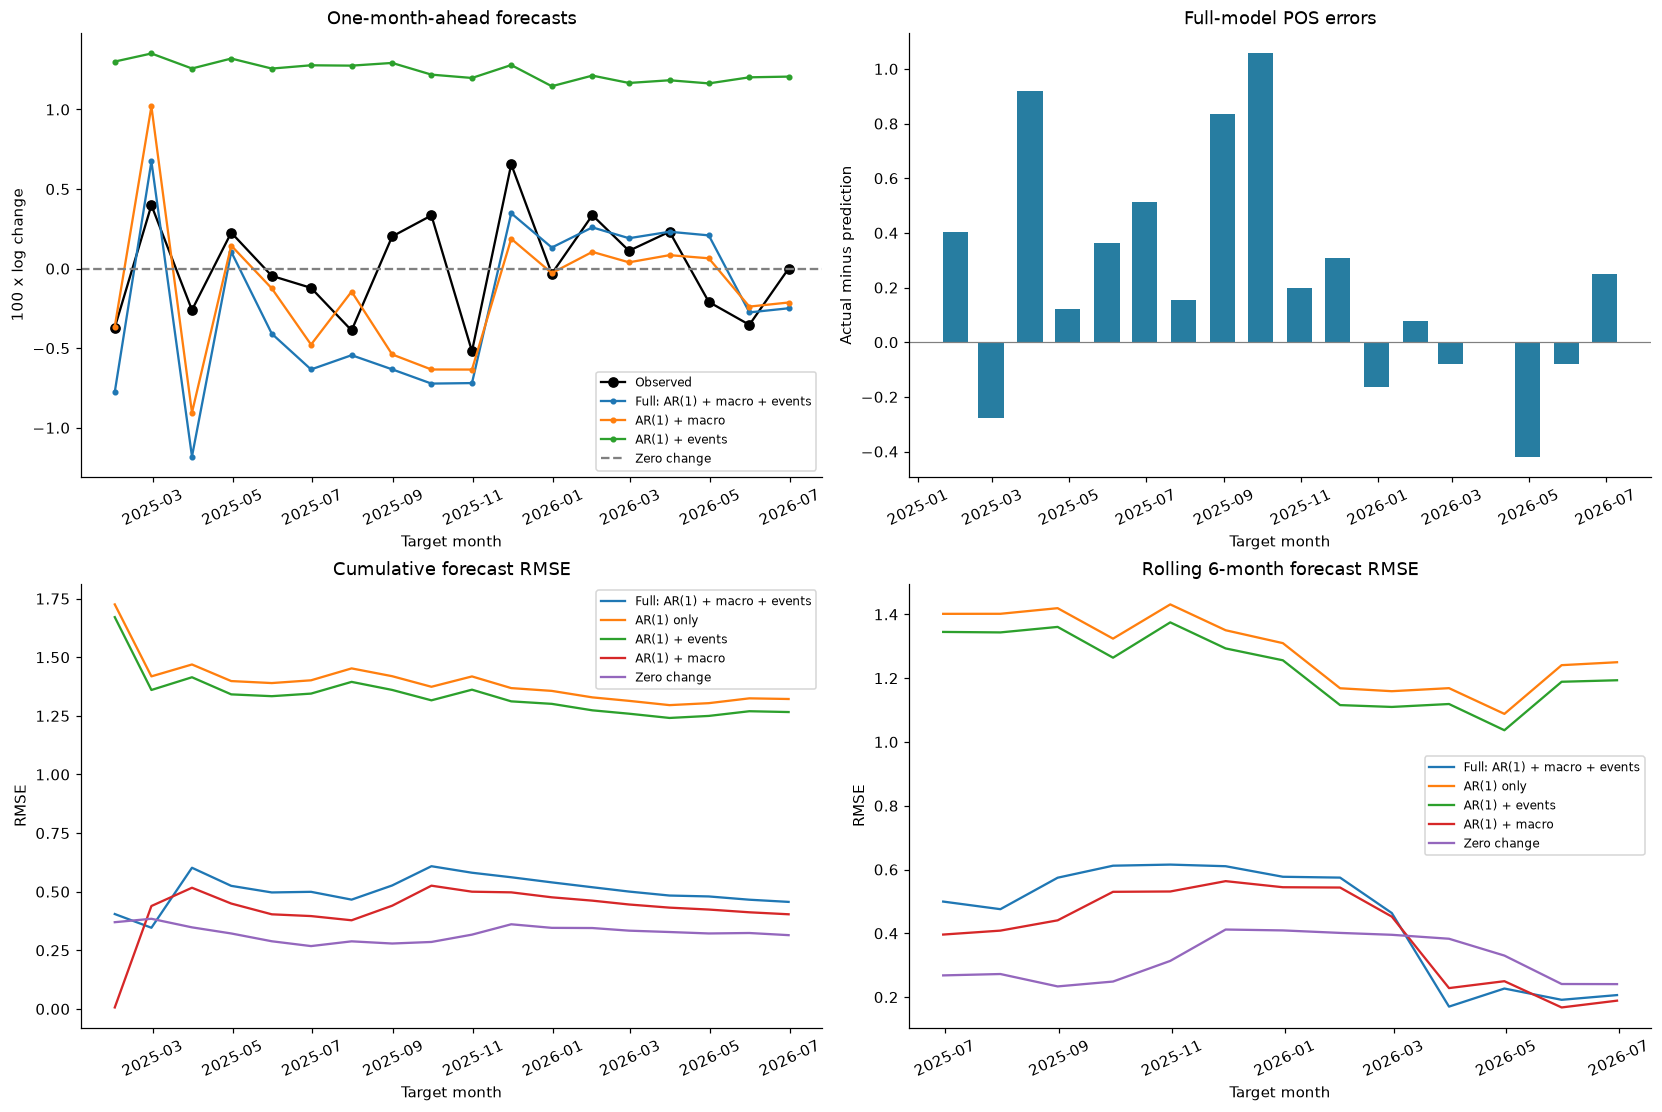

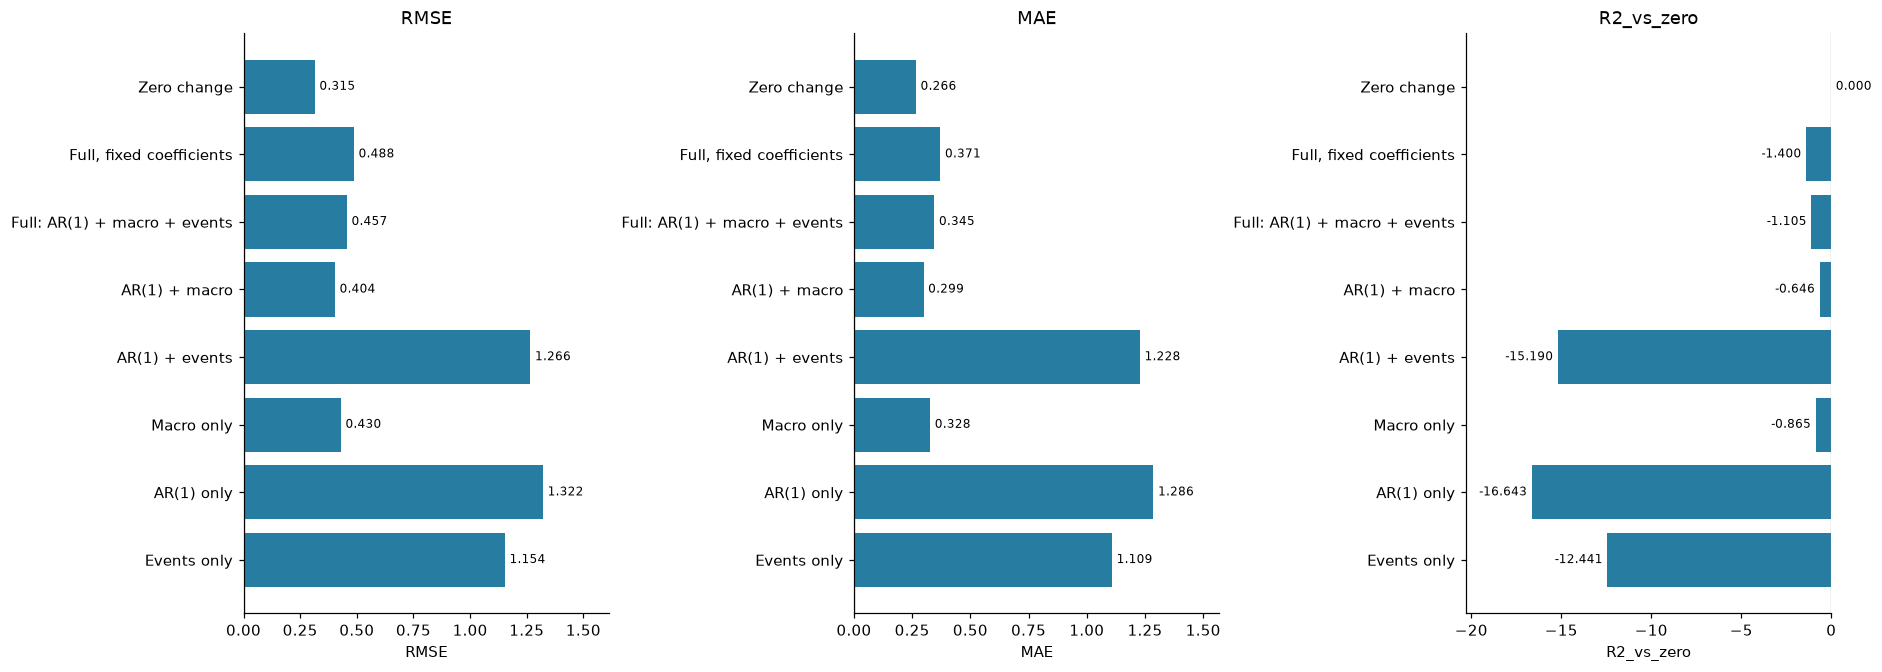

In [8]:
plot_keys = ["full", "ar1", "ar1_events", "ar1_macro", "zero_change"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10), layout="constrained")
axes[0, 0].plot(pos_dates, forecast_log["actual"], color="black", marker="o", label="Observed")
for key in ["full", "ar1_macro", "ar1_events"]:
    axes[0, 0].plot(pos_dates, forecast_log[f"prediction::{key}"], marker=".", label=FORECAST_LABELS[key])
axes[0, 0].axhline(0, color="grey", linestyle="--", label="Zero change")
axes[0, 0].set(title="One-month-ahead forecasts", ylabel="100 x log change")
axes[0, 0].legend(fontsize=8)
axes[0, 1].bar(pos_dates, forecast_log["error::full"], width=20, color="#277DA1")
axes[0, 1].axhline(0, color="grey", linewidth=0.8)
axes[0, 1].set(title="Full-model POS errors", ylabel="Actual minus prediction")
for key in plot_keys:
    axes[1, 0].plot(pos_dates, running_accuracy[f"cumulative_RMSE::{key}"], label=FORECAST_LABELS[key])
    axes[1, 1].plot(pos_dates, running_accuracy[f"rolling_RMSE::{key}"], label=FORECAST_LABELS[key])
axes[1, 0].set(title="Cumulative forecast RMSE", ylabel="RMSE")
axes[1, 1].set(title=f"Rolling {ROLLING_MONTHS}-month forecast RMSE", ylabel="RMSE")
for ax in axes[1]:
    ax.legend(fontsize=8)
for ax in axes.flat:
    ax.set_xlabel("Target month")
    ax.tick_params(axis="x", labelrotation=25)
plt.show()

full_period_accuracy = accuracy_summary.loc[FULL_PERIOD]
fig, axes = plt.subplots(1, 3, figsize=(17, 6), layout="constrained")
for ax, metric in zip(axes, ["RMSE", "MAE", "R2_vs_zero"]):
    series = full_period_accuracy[metric]
    ax.barh(series.index, series.values, color="#277DA1")
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set(title=metric, xlabel=metric)
    for i, value in enumerate(series):
        ax.annotate(
            f"{value:.3f}", (value, i), xytext=(3 if value >= 0 else -3, 0),
            textcoords="offset points", ha="left" if value >= 0 else "right",
            va="center", fontsize=8,
        )
    ax.margins(x=0.22)
plt.show()


**参数与训练拟合的更新 | Parameter and training-fit updates**

七个连续项的系数随拟合截止月展示，最后一个子图为五因子的联合 HAC p 值。另图展示六个模型重估后的训练 R²。这些训练指标与前面的样本外指标含义不同。重复计算的 p 值仅用于描述变化，不构成多次模型选择检验。

The coefficient paths are indexed by the last month included in estimation. The final panel shows the joint macro HAC p-value; a separate figure tracks training R² for all six models. Updated training fit is distinct from forecast accuracy, and repeated p-values are descriptive.


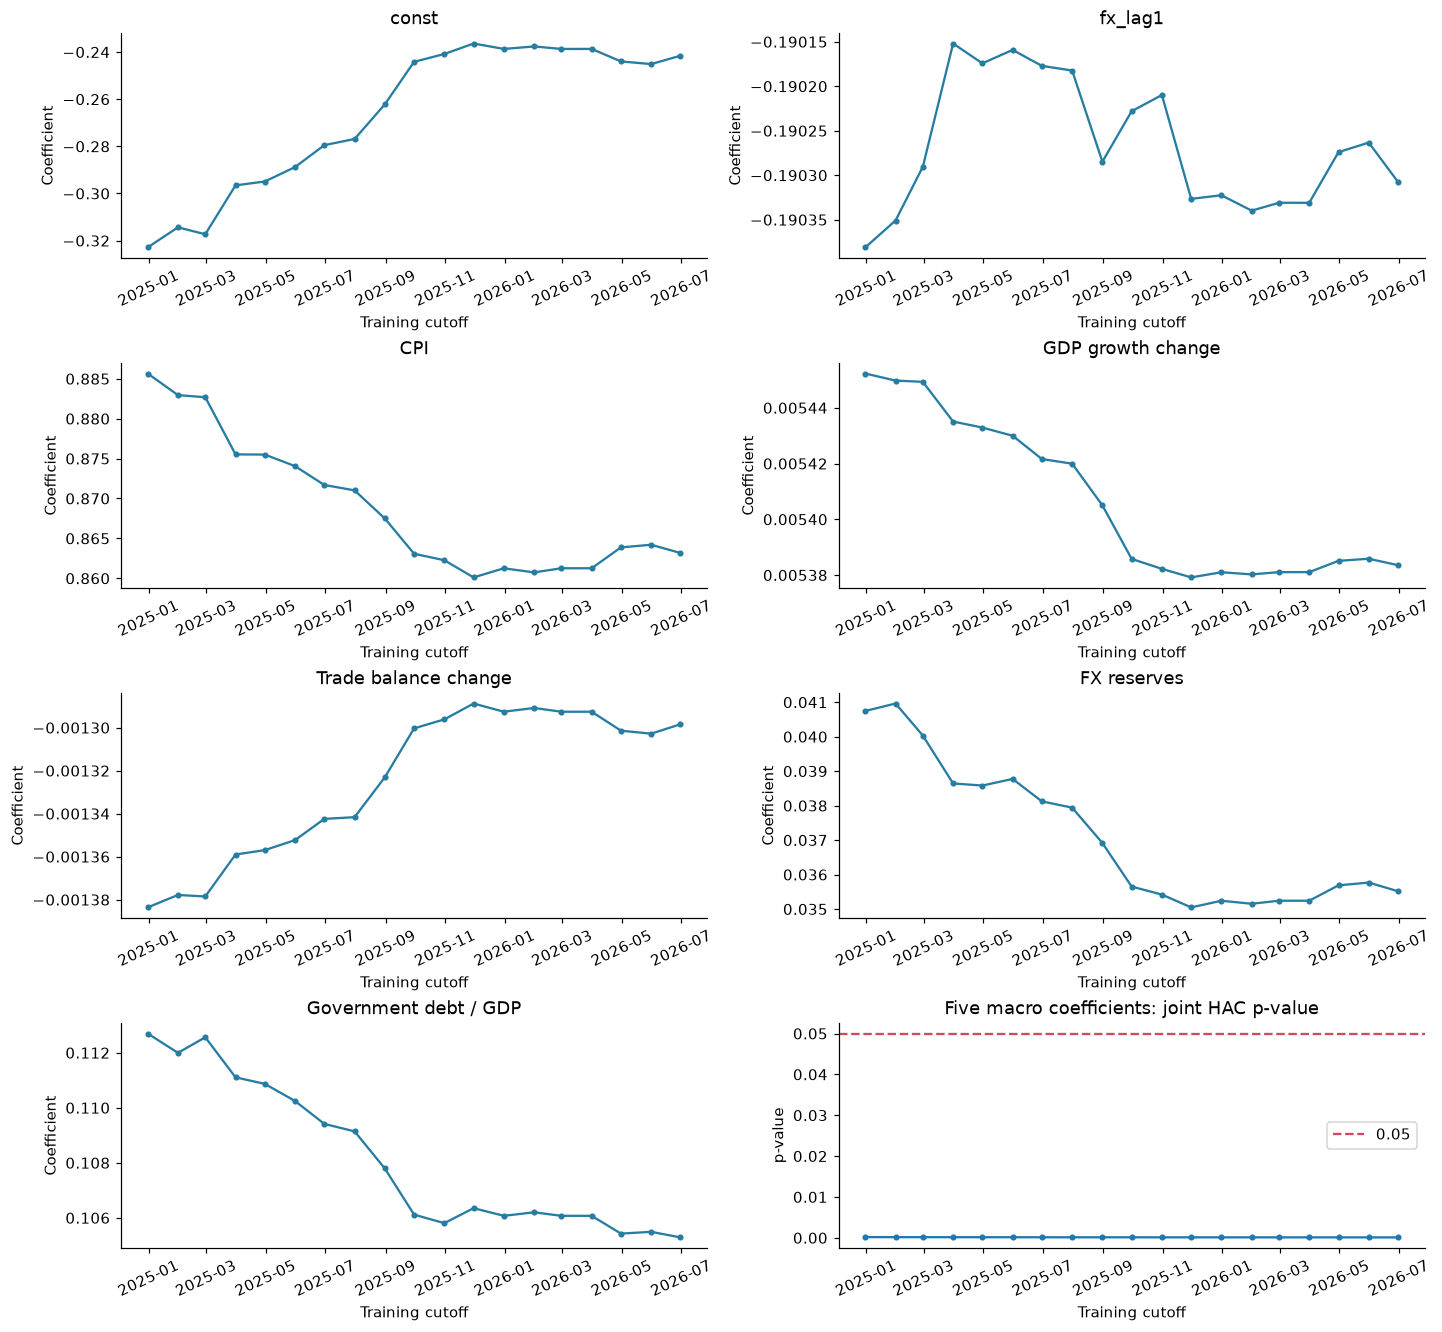

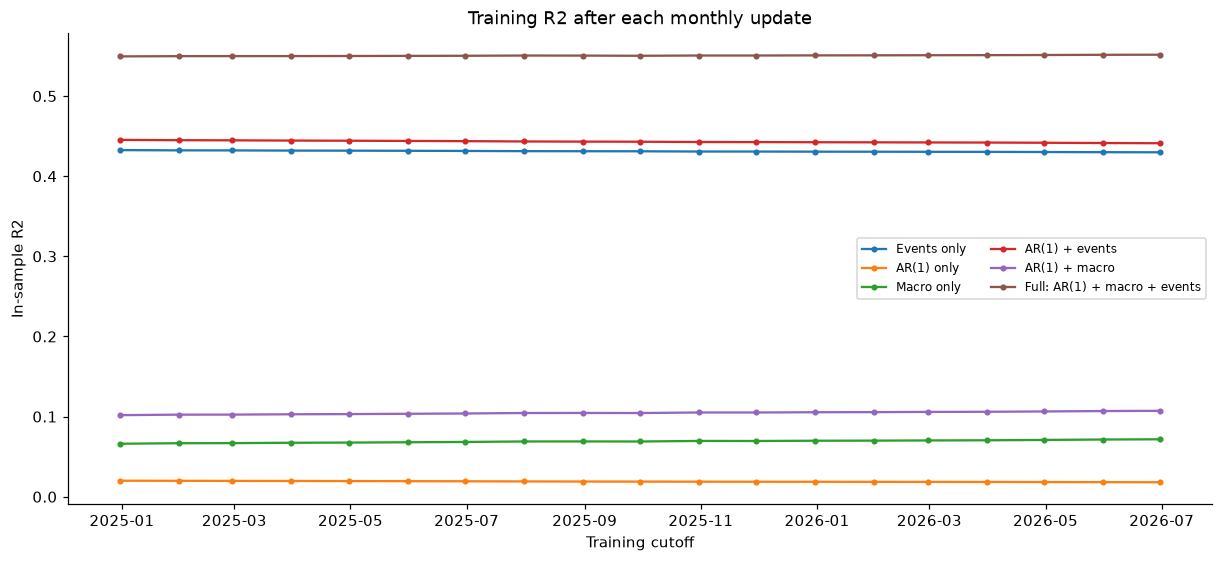

In [9]:
full_parameters = parameter_history.loc[parameter_history["model"].eq("full")].set_index("fit_through")
full_training = training_history.loc[training_history["model"].eq("full")].set_index("fit_through")
fig, axes = plt.subplots(4, 2, figsize=(13, 12), layout="constrained")
for ax, term in zip(axes.flat, ["const", *continuous]):
    ax.plot(full_parameters.index, full_parameters[term], marker=".", color="#277DA1")
    ax.set(title=term, ylabel="Coefficient")
axes.flat[-1].plot(full_training.index, full_training["p_five_macro_joint_HAC"], marker=".")
axes.flat[-1].axhline(ALPHA, color="#D1495B", linestyle="--", label="0.05")
axes.flat[-1].set(title="Five macro coefficients: joint HAC p-value", ylabel="p-value")
axes.flat[-1].legend()
for ax in axes.flat:
    ax.set_xlabel("Training cutoff")
    ax.tick_params(axis="x", labelrotation=25)
plt.show()

fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
for key, label in MODEL_LABELS.items():
    history = training_history.loc[training_history["model"].eq(key)]
    ax.plot(history["fit_through"], history["training_R2"], marker=".", label=label)
ax.set(title="Training R2 after each monthly update", xlabel="Training cutoff", ylabel="In-sample R2")
ax.legend(fontsize=8, ncol=2)
plt.show()
